<a href="https://colab.research.google.com/github/shivamkumar359/3rd-SEM-CLASS-CODES/blob/main/ML_W_10_PRACITCAL_SESSION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [27]:
# customer segmentation practical
# K-MEAN + DBSCAN + INETERACTIVE

In [28]:
!pip -q install plotly

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [30]:
from google.colab import files

In [31]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

print("Libraries imported successfully!")

Libraries imported successfully!


In [32]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mosesmoncy/mall-customerscsv")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'mall-customerscsv' dataset.
Path to dataset files: /kaggle/input/mall-customerscsv


In [33]:
import os
# Locate the CSV file in the downloaded path and load it
csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]
if csv_files:
    df = pd.read_csv(os.path.join(path, csv_files[0]))
    print("Dataset loaded successfully!")
else:
    print("No CSV file found in the downloaded directory.")

# Display the first few rows of the dataframe
df.head()

Dataset loaded successfully!


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [34]:
print("Summary statiscs: ")
display(df.describe())

Summary statiscs: 


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [36]:
print("Missing values: ")
print(df.isnull().sum())

Missing values: 
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [37]:
print("Duplicate rows:", df.duplicated())

Duplicate rows: 0      False
1      False
2      False
3      False
4      False
       ...  
195    False
196    False
197    False
198    False
199    False
Length: 200, dtype: bool


<function matplotlib.pyplot.show(close=None, block=None)>

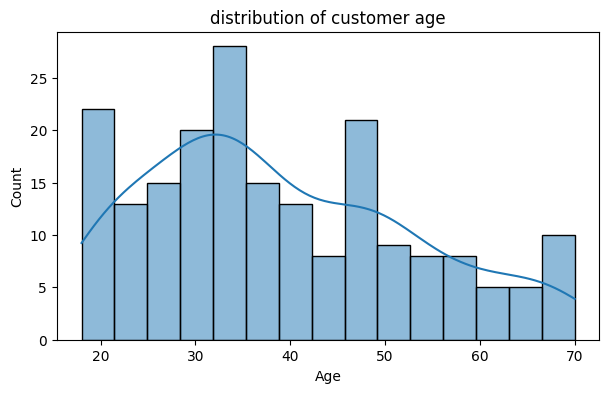

In [45]:
plt.figure(figsize=(7,4))
sns.histplot(df["Age"],bins=15, kde=True)
plt.title("distribution of customer age")

plt.show

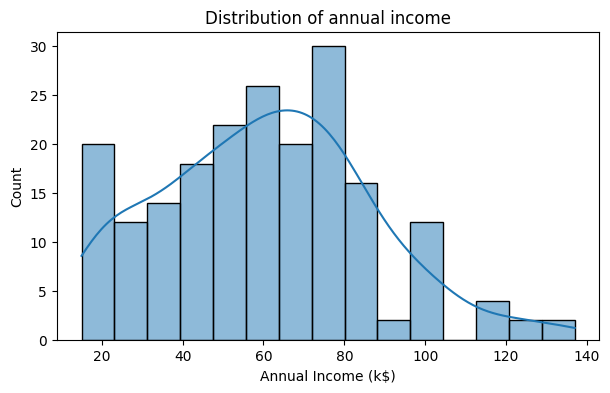

In [50]:
plt.figure(figsize=(7,4))
sns.histplot(df["Annual Income (k$)"], bins=15, kde=True)
plt.title("Distribution of annual income")
plt.show()

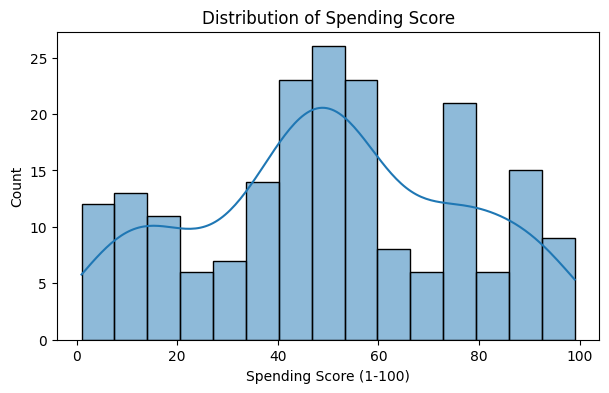

In [52]:
# spending score
plt.figure(figsize=(7,4))
sns.histplot(df["Spending Score (1-100)"], bins=15, kde=True)
plt.title("Distribution of Spending Score")
plt.show()

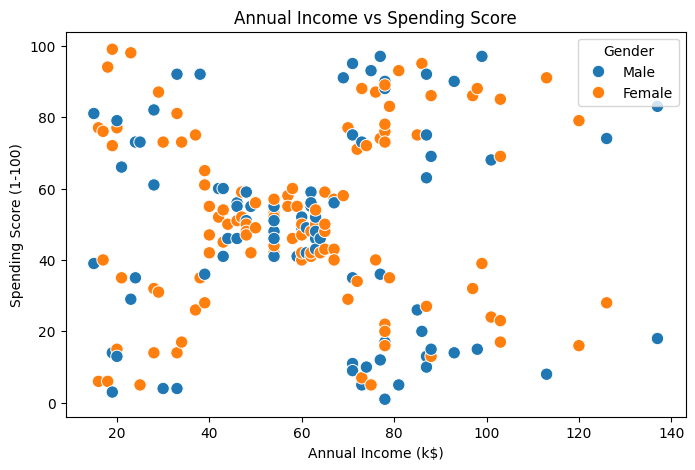

In [54]:
# EXPLORE RELATIONSHIP BETWEEN INCOME AND SPENDING

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Gender",
    s=80
)

plt.title("Annual Income vs Spending Score")
plt.show()

In [58]:
# select features for clustering

X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

In [61]:
# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convert to a DataFrame for easy inspection
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)
print("Scaled features sample:")
display(X_scaled_df.head())

Scaled features sample:


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


In [67]:
# Scaling
# STANDARDIZE THE FEATURES
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Standardized data")
X_scaled[:5]

Standardized data


array([[-1.73899919, -0.43480148],
       [-1.73899919,  1.19570407],
       [-1.70082976, -1.71591298],
       [-1.70082976,  1.04041783],
       [-1.66266033, -0.39597992]])

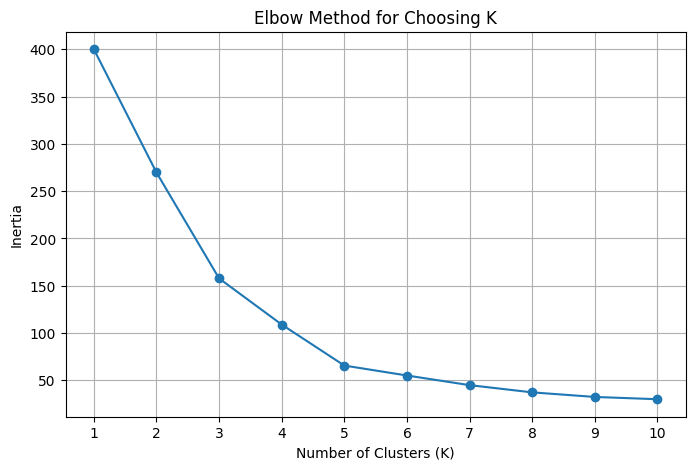

In [70]:
# FIND THE OPTIMAL K USING THE ELBOW METHOD
# Test K-Means with different numbers of cluster
inertia_values = []
for k in range(1, 11):
  model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
  model.fit(X_scaled)
  inertia_values.append(model.inertia_)
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, 11),
    inertia_values,
    marker="o"
)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Choosing K")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [71]:
# EVALUATE CLUSTER COUNTS USING SILHOUETTE SCORE
# Silhouette scores range from -1 to 1.
# Higher scores generally indicate better-separated clusters.
for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
labels = model.fit_predict(X_scaled)
score = silhouette_score(X_scaled, labels)
print("K =", k, "| Silhouette Score =", round(score, 3))

K = 8 | Silhouette Score = 0.455


In [72]:
# BUILD THE K-MEANS MODEL
# Five clusters are a common optimal cluster for this dataset.
# Students should compare this choice with the elbow and scores.
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)
df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)
print("K-Means model completed!")

K-Means model completed!


In [73]:
display(
    df[[
        "CustomerID",
        "Annual Income (k$)",
        "Spending Score (1-100)",
        "KMeans_Cluster"
    ]].head(10)
)

,CustomerID,Annual Income (k$),Spending Score (1-100),KMeans_Cluster
0,1,15,39,4
1,2,15,81,2
2,3,16,6,4
3,4,16,77,2
4,5,17,40,4
5,6,17,76,2
6,7,18,6,4
7,8,18,94,2
8,9,19,3,4
9,10,19,72,2


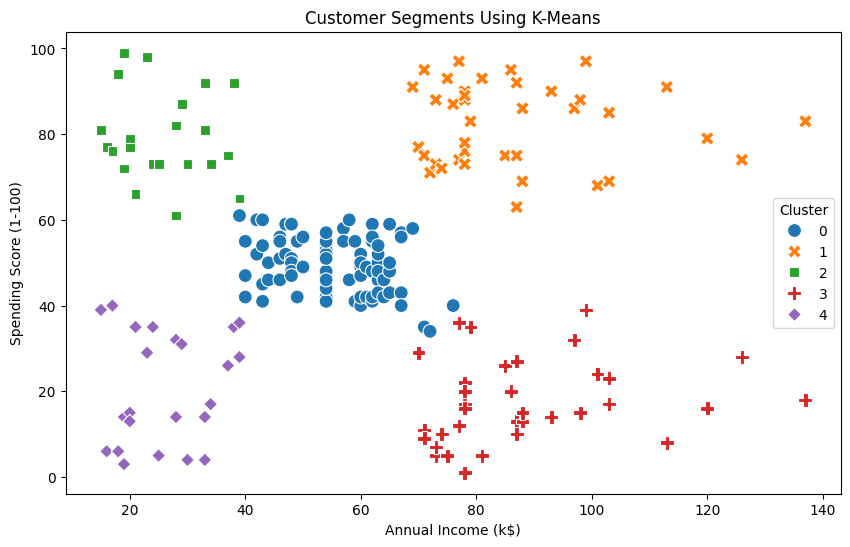

In [75]:
# VISUALIZE K-MEANS CLUSTERS

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="KMeans_Cluster",
    palette="tab10",
    s=100,
    style="KMeans_Cluster"
)

plt.title("Customer Segments Using K-Means")
plt.legend(title="Cluster")
plt.show()

In [76]:
# INTERPRET THE CUSTOMER SEGMENTS

# Calculate the average income and spending score
# for each cluster.

cluster_summary = df.groupby("KMeans_Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending=("Spending Score (1-100)", "mean")
).round(2)

print("Customer Segment Summary:")
display(cluster_summary)

Customer Segment Summary:


,Customer_Count,Average_Age,Average_Income,Average_Spending
KMeans_Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91
